<a href="https://colab.research.google.com/github/asrevo-applied-ml/basic-ml/blob/main/classifications.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classification

### Import Libs

In [133]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import sqrt
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score,recall_score,f1_score,precision_recall_curve,roc_curve,roc_auc_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score,cross_val_predict

### load dataset

In [105]:
from sklearn.datasets import fetch_openml
d=fetch_openml('mnist_784', version=1, as_frame=False, parser='auto')

In [106]:
data,target,categories=d["data"],d["target"],d["categories"]["class"]

In [107]:
data.shape

(70000, 784)

In [108]:
target.shape

(70000,)

In [109]:
categories

['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']

## EDA

In [110]:
def show_img(img_data):
  mn=img_data.shape[0]
  m=int(sqrt(mn))
  number=img_data.reshape((m,m))
  plt.imshow(number,cmap="binary")


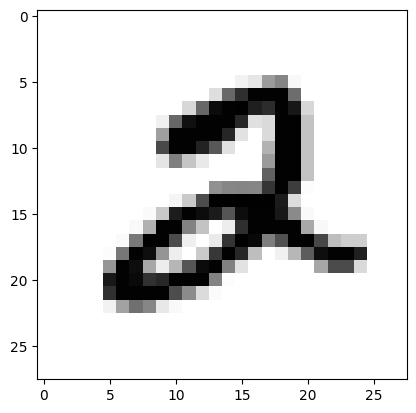

In [111]:
show_img(data[5])

### split the data

In [112]:
x_train,y_train,x_test,y_test=data[:60000],target[:60000],data[60000:],target[60000:]

# tag the target as is 5 or not

In [113]:
y_train_5=y_train=='5'
y_test_5=y_test=='5'

try Dummy classifier accuricy

### hint a dummy classifier getting a a percentage of accuracy 9/10  

In [114]:
cross_val_score(DummyClassifier(),x_train,y_train_5,cv=3,scoring="accuracy")

array([0.90965, 0.90965, 0.90965])

SDG classifier

#### **accurcy** percent of correct vs wrong predictions

In [115]:
cross_val_score(SGDClassifier(random_state=42),x_train,y_train_5,cv=3,scoring="accuracy")

array([0.95035, 0.96035, 0.9604 ])

In [116]:
y_train_predict=cross_val_predict(SGDClassifier(random_state=42),x_train,y_train_5,cv=3)

### *confixan matrix*

In [117]:
confusion_matrix(y_train_5,y_train_predict)

array([[53892,   687],
       [ 1891,  3530]])

##  **recal** *TPR* percent of correct predict of true of all true class
### 3430/3530+1891

In [118]:
recall_score(y_train_5,y_train_predict)

0.6511713705958311

### **65%** of all images that has 5 i was able to predict it and classify them as 5

## **Precission**. from all true predication we did , what is the  correct percentage
### 3530/3530+687



In [119]:
precision_score(y_train_5,y_train_predict)

0.8370879772350012

### **F1 score** harmonic mean that claculate average and give high wight to small values ( **recall** , **percission** )

In [120]:
f1_score(y_train_5,y_train_predict)

0.7325171197343847

## **Precission vs Recall** trade off

In [121]:
y_train_predict=cross_val_predict(SGDClassifier(random_state=42),x_train,y_train_5,cv=3)

In [122]:
confusion_matrix(y_train_5,y_train_predict)

array([[53892,   687],
       [ 1891,  3530]])

In [123]:
print(f"precision = {precision_score(y_train_5,y_train_predict)} , recall = {recall_score(y_train_5,y_train_predict)} , f_score = {f1_score(y_train_5,y_train_predict)}")


precision = 0.8370879772350012 , recall = 0.6511713705958311 , f_score = 0.7325171197343847


In [124]:
cls=SGDClassifier(random_state=42)
cls.fit(x_train,y_train_5)


SGDClassifier(random_state=42)

In [125]:
y_score=cls.decision_function([x_train[0]])  # get probability
y_score

array([2164.22030239])

In [126]:
threshold=0

In [127]:
y_score>threshold

array([ True])

In [128]:
threshold=3000
y_score>threshold


array([False])

In [129]:
y_scores=cross_val_predict(SGDClassifier(random_state=42),x_train,y_train_5,cv=3,method="decision_function")

In [130]:
precisions,recalls,thresholds=precision_recall_curve(y_train_5,y_scores)

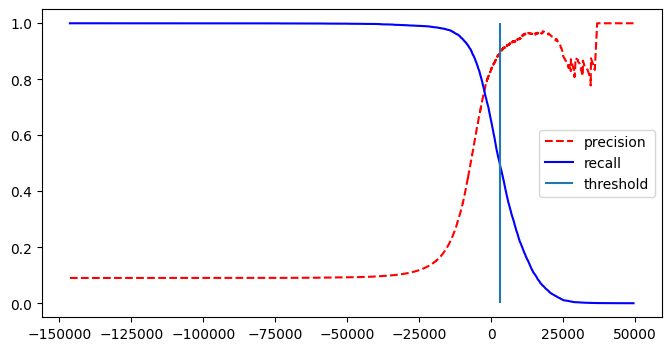

In [131]:
plt.figure(figsize=(8, 4))
plt.plot(thresholds,precisions[:-1],color="red",linestyle="--",label="precision")
plt.plot(thresholds,recalls[:-1],color="blue",linestyle="-",label="recall")
plt.vlines(threshold,0,1,label="threshold")
plt.legend(loc="center right")
plt.show()

In [132]:
max_precision_idx=(precisions>=.9).argmax()
precisions[max_precision_idx],recalls[max_precision_idx],thresholds[max_precision_idx]

(np.float64(0.9000345901072293),
 np.float64(0.4799852425751706),
 np.float64(3370.0194991439557))

# Multiclass classification

In [139]:
clf=SVC()
clf.fit(x_train,y_train)

SVC()

In [140]:
clf.predict([x_train[0]])

array(['5'], dtype=object)

In [142]:
clf.decision_function([x_train[0]])

array([[ 1.72501977,  2.72809088,  7.2510018 ,  8.3076379 , -0.31087254,
         9.3132482 ,  1.70975103,  2.76765202,  6.23049537,  4.84771048]])

In [143]:
clf.classes_

array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype=object)